In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import LeaveOneOut, cross_val_predict
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

data_path = Path("../data/mpcvd_experimental_data_v01.csv")
results_path = Path("../results")
results_path.mkdir(parents=True, exist_ok=True)

data = pd.read_csv(data_path)

print("Dataset shape:", data.shape)
display(data)

Dataset shape: (6, 5)


,observation_id,temperature_c,methane_pct,growth_rate_um_h,series_id
0,1,800,4,0.60,2
1,2,800,20,3.41,2
2,3,800,100,0.60,2
3,4,900,3,2.80,3
4,5,900,40,4.10,3
5,6,900,100,2.10,3


In [2]:
required_columns = [
    "observation_id",
    "temperature_c",
    "methane_pct",
    "growth_rate_um_h",
    "series_id"
]

assert list(data.columns) == required_columns
assert len(data) == 6
assert not data.isnull().any().any()
assert not data.duplicated().any()
assert not data["observation_id"].duplicated().any()
assert not data.duplicated(
    subset=["temperature_c", "methane_pct"]
).any()

numeric_columns = [
    "temperature_c",
    "methane_pct",
    "growth_rate_um_h"
]

assert np.isfinite(data[numeric_columns].to_numpy()).all()
assert data["methane_pct"].between(0, 100).all()
assert (data["growth_rate_um_h"] >= 0).all()

print("Data validation passed.")
print("\nColumn types:")
print(data.dtypes)

Data validation passed.

Column types:
observation_id        int64
temperature_c         int64
methane_pct           int64
growth_rate_um_h    float64
series_id             int64
dtype: object


In [3]:
print("Descriptive Statistics")
display(data.describe().round(4))

growth = data["growth_rate_um_h"]

print("Mean:", round(growth.mean(), 4))
print("Median:", round(growth.median(), 4))
print("Standard deviation:", round(growth.std(), 4))
print("Minimum:", growth.min())
print("Maximum:", growth.max())

correlation = data["methane_pct"].corr(growth)

print("Pearson correlation:", round(correlation, 4))

Descriptive Statistics


,observation_id,temperature_c,methane_pct,growth_rate_um_h,series_id
count,6.0000,6.0000,6.0000,6.0000,6.0000
mean,3.5000,850.0000,44.5000,2.2683,2.5000
std,1.8708,54.7723,45.0411,1.4516,0.5477
min,1.0000,800.0000,3.0000,0.6000,2.0000
25%,2.2500,800.0000,8.0000,0.9750,2.0000
50%,3.5000,850.0000,30.0000,2.4500,2.5000
75%,4.7500,900.0000,85.0000,3.2575,3.0000
max,6.0000,900.0000,100.0000,4.1000,3.0000


Mean: 2.2683
Median: 2.45
Standard deviation: 1.4516
Minimum: 0.6
Maximum: 4.1
Pearson correlation: -0.2834


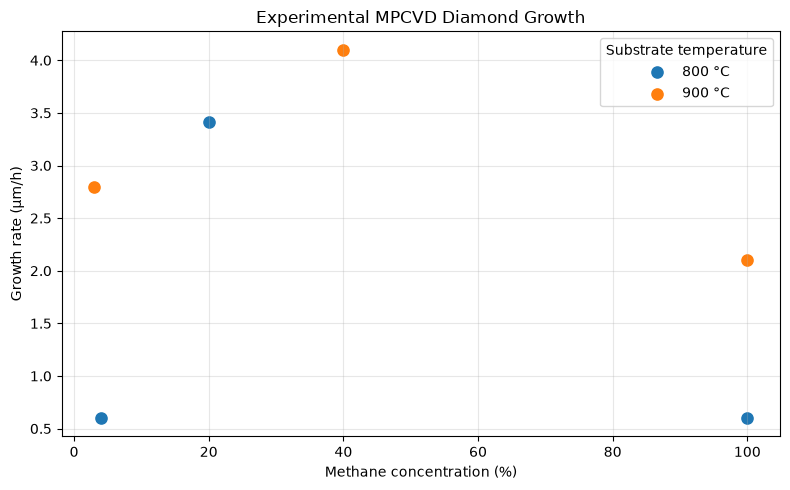

In [4]:
fig, ax = plt.subplots(figsize=(8, 5))

for temperature in sorted(data["temperature_c"].unique()):
    subset = data[data["temperature_c"] == temperature]

    ax.scatter(
        subset["methane_pct"],
        subset["growth_rate_um_h"],
        label=f"{temperature} °C",
        s=65
    )

ax.set_xlabel("Methane concentration (%)")
ax.set_ylabel("Growth rate (µm/h)")
ax.set_title("Experimental MPCVD Diamond Growth")
ax.legend(title="Substrate temperature")
ax.grid(True, alpha=0.3)

fig.tight_layout()

fig.savefig(
    results_path / "figure_1_experimental_growth.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [5]:
X_linear = data[["methane_pct", "temperature_c"]]
y = data["growth_rate_um_h"]

linear_model = LinearRegression()
linear_model.fit(X_linear, y)

linear_predictions = linear_model.predict(X_linear)

linear_mae = mean_absolute_error(y, linear_predictions)
linear_rmse = np.sqrt(mean_squared_error(y, linear_predictions))
linear_r2 = r2_score(y, linear_predictions)

print("Multiple Linear Regression")
print("Intercept:", round(linear_model.intercept_, 6))
print("Methane coefficient:", round(linear_model.coef_[0], 6))
print("Temperature coefficient:", round(linear_model.coef_[1], 6))

print("\nMAE:", round(linear_mae, 4))
print("RMSE:", round(linear_rmse, 4))
print("R²:", round(linear_r2, 4))

Multiple Linear Regression
Intercept: -10.268622
Methane coefficient: -0.010567
Temperature coefficient: 0.015303

MAE: 0.889
RMSE: 1.0164
R²: 0.4117


In [6]:
X_methane = data[["methane_pct"]]

quadratic_model = make_pipeline(
    PolynomialFeatures(degree=2, include_bias=False),
    LinearRegression()
)

quadratic_model.fit(X_methane, y)

quadratic_predictions = quadratic_model.predict(X_methane)

quadratic_mae = mean_absolute_error(y, quadratic_predictions)
quadratic_rmse = np.sqrt(mean_squared_error(y, quadratic_predictions))
quadratic_r2 = r2_score(y, quadratic_predictions)

quadratic_regression = quadratic_model.named_steps["linearregression"]

print("Quadratic Methane Regression")
print("Intercept:", round(quadratic_regression.intercept_, 6))
print("Methane coefficient:", round(quadratic_regression.coef_[0], 6))
print("Methane squared coefficient:", round(quadratic_regression.coef_[1], 6))

print("\nMAE:", round(quadratic_mae, 4))
print("RMSE:", round(quadratic_rmse, 4))
print("R²:", round(quadratic_r2, 4))

Quadratic Methane Regression
Intercept: 1.370228
Methane coefficient: 0.116288
Methane squared coefficient: -0.001165

MAE: 0.6743
RMSE: 0.7992
R²: 0.6363


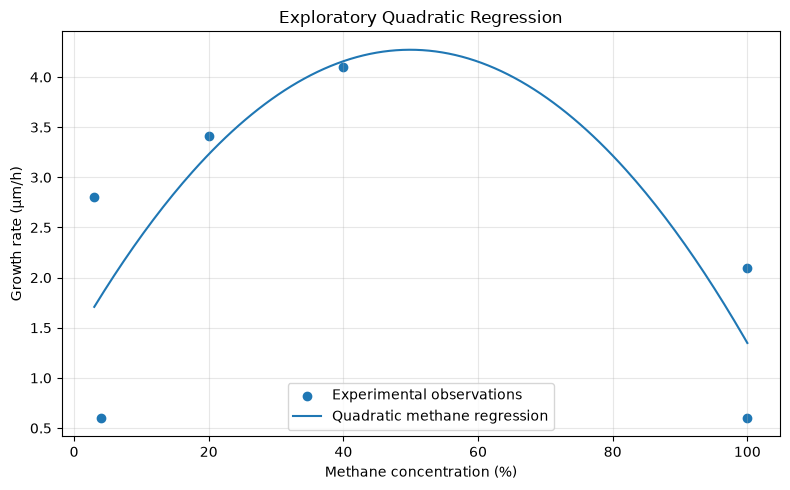

In [7]:
methane_range = np.linspace(
    data["methane_pct"].min(),
    data["methane_pct"].max(),
    200
)

curve_input = pd.DataFrame({
    "methane_pct": methane_range
})

curve_predictions = quadratic_model.predict(curve_input)

fig, ax = plt.subplots(figsize=(8, 5))

ax.scatter(
    data["methane_pct"],
    y,
    label="Experimental observations"
)

ax.plot(
    methane_range,
    curve_predictions,
    label="Quadratic methane regression"
)

ax.set_xlabel("Methane concentration (%)")
ax.set_ylabel("Growth rate (µm/h)")
ax.set_title("Exploratory Quadratic Regression")
ax.legend()
ax.grid(True, alpha=0.3)

fig.tight_layout()
plt.show()

In [8]:
evaluation_results = pd.DataFrame({
    "Model": [
        "Multiple Linear Regression",
        "Quadratic Methane Regression"
    ],
    "MAE (µm/h)": [linear_mae, quadratic_mae],
    "RMSE (µm/h)": [linear_rmse, quadratic_rmse],
    "R²": [linear_r2, quadratic_r2]
})

display(evaluation_results.round(4))

,Model,MAE (µm/h),RMSE (µm/h),R²
0,Multiple Linear Regression,0.8890,1.0164,0.4117
1,Quadratic Methane Regression,0.6743,0.7992,0.6363


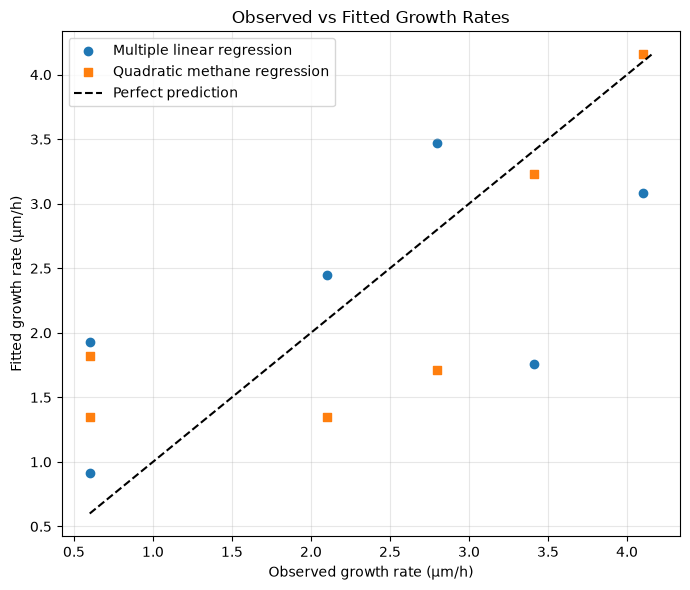

In [9]:
fig, ax = plt.subplots(figsize=(7, 6))

ax.scatter(
    y,
    linear_predictions,
    label="Multiple linear regression"
)

ax.scatter(
    y,
    quadratic_predictions,
    label="Quadratic methane regression",
    marker="s"
)

all_values = np.concatenate([
    y.to_numpy(),
    linear_predictions,
    quadratic_predictions
])

lower = all_values.min()
upper = all_values.max()

ax.plot(
    [lower, upper],
    [lower, upper],
    "--",
    color="black",
    label="Perfect prediction"
)

ax.set_xlabel("Observed growth rate (µm/h)")
ax.set_ylabel("Fitted growth rate (µm/h)")
ax.set_title("Observed vs Fitted Growth Rates")
ax.legend()
ax.grid(True, alpha=0.3)

fig.tight_layout()

fig.savefig(
    results_path / "figure_2_model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [10]:
loo = LeaveOneOut()

linear_cv_predictions = cross_val_predict(
    LinearRegression(),
    X_linear,
    y,
    cv=loo
)

quadratic_cv_predictions = cross_val_predict(
    make_pipeline(
        PolynomialFeatures(degree=2, include_bias=False),
        LinearRegression()
    ),
    X_methane,
    y,
    cv=loo
)

cv_results = pd.DataFrame({
    "Model": [
        "Multiple Linear Regression",
        "Quadratic Methane Regression"
    ],
    "LOOCV MAE": [
        mean_absolute_error(y, linear_cv_predictions),
        mean_absolute_error(y, quadratic_cv_predictions)
    ],
    "LOOCV RMSE": [
        np.sqrt(mean_squared_error(y, linear_cv_predictions)),
        np.sqrt(mean_squared_error(y, quadratic_cv_predictions))
    ]
})

display(cv_results.round(4))

,Model,LOOCV MAE,LOOCV RMSE
0,Multiple Linear Regression,1.6663,1.8040
1,Quadratic Methane Regression,1.3012,1.5232


Methane concentration: 20 %
Substrate temperature: 800 °C
Growth duration: 5 hours
Predicted growth rate: 1.762 µm/h
Predicted thickness: 8.81 µm


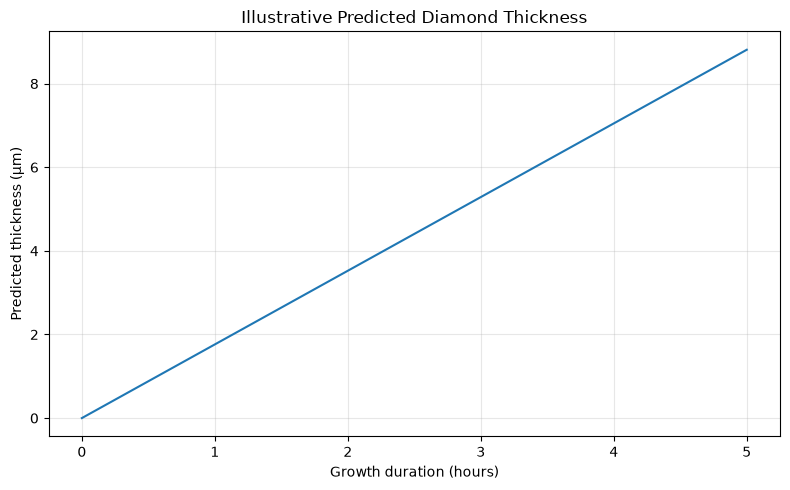

In [11]:
# Reference operating conditions
methane_pct = 20
temperature_c = 800
duration_h = 5

reference_input = pd.DataFrame({
    "methane_pct": [methane_pct],
    "temperature_c": [temperature_c]
})

predicted_growth_rate = linear_model.predict(reference_input)[0]

predicted_thickness = predicted_growth_rate * duration_h

print("Methane concentration:", methane_pct, "%")
print("Substrate temperature:", temperature_c, "°C")
print("Growth duration:", duration_h, "hours")
print("Predicted growth rate:", round(predicted_growth_rate, 3), "µm/h")
print("Predicted thickness:", round(predicted_thickness, 3), "µm")

# Illustrative thickness graph
time_values = np.linspace(0, duration_h, 100)
thickness_values = predicted_growth_rate * time_values

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(time_values, thickness_values)

ax.set_xlabel("Growth duration (hours)")
ax.set_ylabel("Predicted thickness (µm)")
ax.set_title("Illustrative Predicted Diamond Thickness")
ax.grid(True, alpha=0.3)

fig.tight_layout()

fig.savefig(
    results_path / "figure_3_predicted_thickness.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [12]:
results_table = data.copy()

results_table["predicted_growth_um_h"] = linear_predictions

results_table["residual_um_h"] = (
    results_table["growth_rate_um_h"]
    - results_table["predicted_growth_um_h"]
)

results_table.to_csv(
    results_path / "linear_regression_results.csv",
    index=False
)

print("Results saved successfully.")
print("Output folder:", results_path.resolve())

display(results_table.round(4))

print("\nExploratory analysis completed.")
print("Models are not independently experimentally validated.")

Results saved successfully.
Output folder: /Users/faseehatakolia/Documents/diamond-growth-optimisation/results


,observation_id,temperature_c,methane_pct,growth_rate_um_h,series_id,predicted_growth_um_h,residual_um_h
0,1,800,4,0.60,2,1.9312,-1.3312
1,2,800,20,3.41,2,1.7621,1.6479
2,3,800,100,0.60,2,0.9168,-0.3168
3,4,900,3,2.80,3,3.4720,-0.6720
4,5,900,40,4.10,3,3.0810,1.0190
5,6,900,100,2.10,3,2.4470,-0.3470



Exploratory analysis completed.
Models are not independently experimentally validated.
